In [1]:
import numpy as np
import os
import math

import matplotlib.pyplot as plt

#plt.rc('font', size=10)          # controls default text sizes
#plt.rc('axes', titlesize=14)     # fontsize of the axes title
#plt.rc('axes', labelsize=14)    # fontsize of the x and y labels
#plt.rc('xtick', labelsize=12)    # fontsize of the tick labels
#plt.rc('ytick', labelsize=12)    # fontsize of the tick labels
#plt.rc('legend', fontsize=12)    # legend fontsize

plt.rc('font', size=14)          # controls default text sizes
plt.rc('axes', titlesize=18)     # fontsize of the axes title
plt.rc('axes', labelsize=18)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=16)    # fontsize of the tick labels
plt.rc('ytick', labelsize=16)    # fontsize of the tick labels
plt.rc('legend', fontsize=14)    # legend fontsize

import sys
sys.path.append('/home/staff7/fbsskr/Notebooks/optimalrcs-cupy/')
import optimalrcs,metrics,plots

In [2]:
# Parameters
m = 1.0  # mass
gamma = 1.0  # friction coefficient
k_B = 1.0  # Boltzmann constant
T = 1.0  # temperature
dt = 0.005  # time step
num_steps = 3000000  # number of steps
x0 = -0.17# initial position
v0 = 0.0  # initial velocity

wall_dx  = 0.1
k = 100
bleft  = -0.25
bright = 0.25
deltaf = 1.2
height = 0.15
width = 0.1
dB = 0

# Potential function U(x)
def potential(x):
    #return -math.exp(-(x-0.5)**2/0.04)*1.5
    L = bright - bleft     # width of 1 bump
    xleft = bleft - wall_dx - width
    xright = bright + wall_dx + width

    if x < xleft:
        v_pot = k*(x-xleft)**2/2.
    elif x > xright:
        v_pot = k*(x-xright)**2/2.
    elif x < bleft-width:
        v_pot = np.zeros_like(x)
    elif x > bright+width:
        v_pot = np.zeros_like(x) + dB*height
    elif x < bleft:
        v_pot = height/2 * (1 - np.cos(np.pi*(x-bleft+width)/width))
    elif x > bright:
        v_pot = (1-dB)*height/2 * (1 - np.cos(np.pi*(x-bright-width)/width)) + dB*height
    else:
        v_pot = height + deltaf/2 * (-1 + np.cos(2*np.pi*(x-bleft)/L))

    return v_pot.sum()

# Gradient of the potential (force)
def force(x):
    #return -(x-0.5)*2/0.04*math.exp(-(x-0.5)**2/0.04)*1.5
    
    L = bright - bleft     # width of 1 bump
    xleft = bleft - wall_dx - width
    xright = bright + wall_dx + width

    if x < xleft:
        force = -k*(x-xleft)
    elif x > xright:
        force = -k*(x-xright)
    elif (x < bleft-width) or (x > bright+width):
            force = 0
    elif x < bleft:
        force = -height*np.pi / (2*width) * np.sin(np.pi*(x-bleft+width)/width)
    elif x > bright:
        force = -(1-dB)*height*np.pi / (2*width) * np.sin(np.pi*(x-bright-width)/width)
    else:
        force =  np.pi * deltaf/L * np.sin(2*np.pi*(x-bleft)/L) 

    # forces = np.ones(1) * force
    # virial = np.zeros((1,1))

    return force

# Initialize arrays to store positions and velocities
positions = np.zeros(num_steps)
velocities = np.zeros(num_steps)

# Initial conditions
positions[0] = x0
velocities[0] = v0

# GJF coefficients
a = (1 - gamma*dt/(2*m)) / (1 + gamma*dt/(2*m))
b = 1 / (1 + gamma*dt/(2*m))
# Random impulse standard deviation
sigma = np.sqrt(2*gamma*k_B*T*dt)
# Initial random 
rng = np.random.default_rng(0)
beta = sigma * rng.standard_normal(num_steps)

np.random.seed(0)
# Simulation loop
for i in range(1, num_steps):
    x = positions[i-1]
    v = velocities[i-1]
    
    # Calculate forces
    F = force(x)
    
    # Generate random noise
    #xi = np.random.normal(0, 1)
    
    # Update velocity and position using the Euler-Maruyama method
    #v = v + (-gamma * v + F / m) * dt + np.sqrt(2 * gamma * k_B * T / m) * xi * np.sqrt(dt)
    #x = x + v * dt

    #bjf
    bi = beta[i]

    x_new = x + b*dt*v + b*dt**2/(2*m)*F + b*dt/(2*m)*bi
    F_new = force(x_new)
    v = a*v + dt/(2*m)*(a*F + F_new) + b/m*bi

    x, F = x_new, F_new
    
    # Apply boundary conditions (reflective walls)
    #if x < 0:
     #   x = 0
      #  v = -v  # Reflect velocity
    #elif x > 1:
    #    x = 1
    #    v = -v  # Reflect velocity
    
    # Store positions and velocities
    positions[i] = x
    velocities[i] = v

# Plot the results
time = np.linspace(0, num_steps * dt, num_steps)
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(time[:1000], positions[:1000])
plt.xlabel('Time')
plt.ylabel('Position')
plt.title('Position vs Time')

plt.subplot(1, 2, 2)
plt.hist(positions, bins=50, density=True)
plt.xlabel('Position')
plt.ylabel('Probability density')
plt.title('Position Distribution')

plt.tight_layout()
plt.show()


i_traj=np.ones_like(positions)
t_traj=np.asarray(range(len(positions)))
from scipy.interpolate import griddata

def qxv(q,x,v):

    xi = np.linspace(-0.35, 0.35, 100)
    vi = np.linspace(-3, 3, 100)
    xi, vi = np.meshgrid(xi, vi)

    qi = griddata((x, v), q, (xi, vi), method='cubic')
    qi = np.clip(qi, 0, 1)
    levels = [0, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.98, 0.99, 1]

    
    # Create the contour plot with specified contour lines
    contour = plt.contourf(xi, vi, qi, levels=levels, cmap="RdBu_r")
    contour_lines = plt.contour(xi, vi, qi, levels=levels, colors='grey', alpha=0.5)

    plt.colorbar(contour, label='q value')
    plt.xlabel('x')
    plt.ylabel('v')
    plt.title('Contour plot of q(x, v)')
    plt.grid()
    plt.show()
    
    
def comp_y(): return positions

history=[0,1]
yr_type=['y(t-d),y(t)']

q=optimalrcs.CommittorNE(boundary0=positions<-0.35,boundary1=positions>0.35, i_traj=i_traj, t_traj=t_traj)
np.random.seed(0)
optimalrcs.envelope_scale=1000000
q.fit_transform(comp_y,history_delta_t=history,gamma=0,max_iter=2000,history_type=yr_type, history_shift_type='r(t)',delta_r2_max_change_allowed=10000)
optimalrcs.envelope_scale=0.01
q.fit_transform(comp_y,history_delta_t=history,gamma=0,max_iter=10000,history_type=yr_type, history_shift_type='r(t)')

q.plots_feps(delta_t_sim=0.01)
q.plots_obs_pred()
q.plots_obs_pred(log_scale=True)
plt.show()
qxv(q.r_traj.get(),positions,velocities)

NameError: name 'x' is not defined

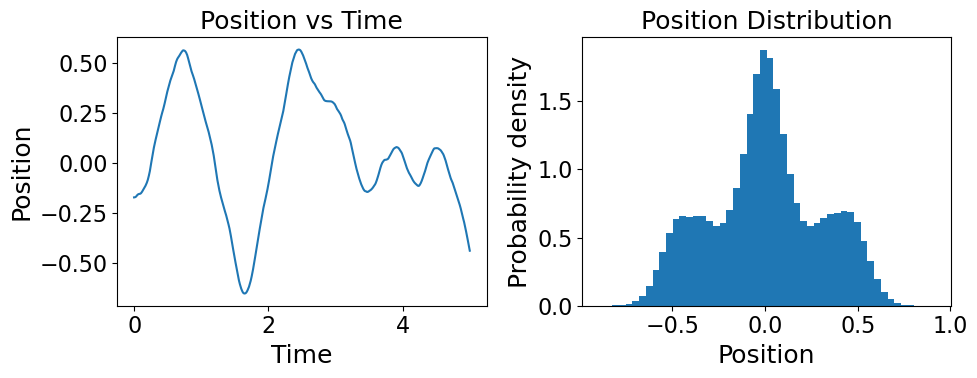

#=1000, xent=0.462659, mse=0.163709, sdzq=710.924, dzq=1674.4, dr2=4520.35, auc=0.846765, |dx|=0.242355, time=26.0499
#=2000, xent=0.464434, mse=0.164305, sdzq=741.335, dzq=1731.9, dr2=4447.07, auc=0.846009, |dx|=0.0129472, time=51.6557
#=3000, xent=0.39887, mse=0.138636, sdzq=156.793, dzq=374.811, dr2=5628.84, auc=0.874143, |dx|=0.173797, time=25.6812
#=4000, xent=0.398347, mse=0.138744, sdzq=161.154, dzq=378.064, dr2=5646.24, auc=0.874207, |dx|=0.00539227, time=51.3293
#=5000, xent=0.398683, mse=0.13875, sdzq=162.382, dzq=377.706, dr2=5640.1, auc=0.874129, |dx|=0.00206967, time=77.2605
#=6000, xent=0.398478, mse=0.138746, sdzq=162.849, dzq=379.362, dr2=5648.55, auc=0.874203, |dx|=0.00136626, time=102.905
#=7000, xent=0.398642, mse=0.138763, sdzq=163.204, dzq=379.861, dr2=5653.48, auc=0.874203, |dx|=0.00123452, time=128.496
#=8000, xent=0.398438, mse=0.138765, sdzq=163.846, dzq=380.991, dr2=5657.71, auc=0.874238, |dx|=0.00104394, time=154.099
#=9000, xent=0.398324, mse=0.13875, sdzq=1

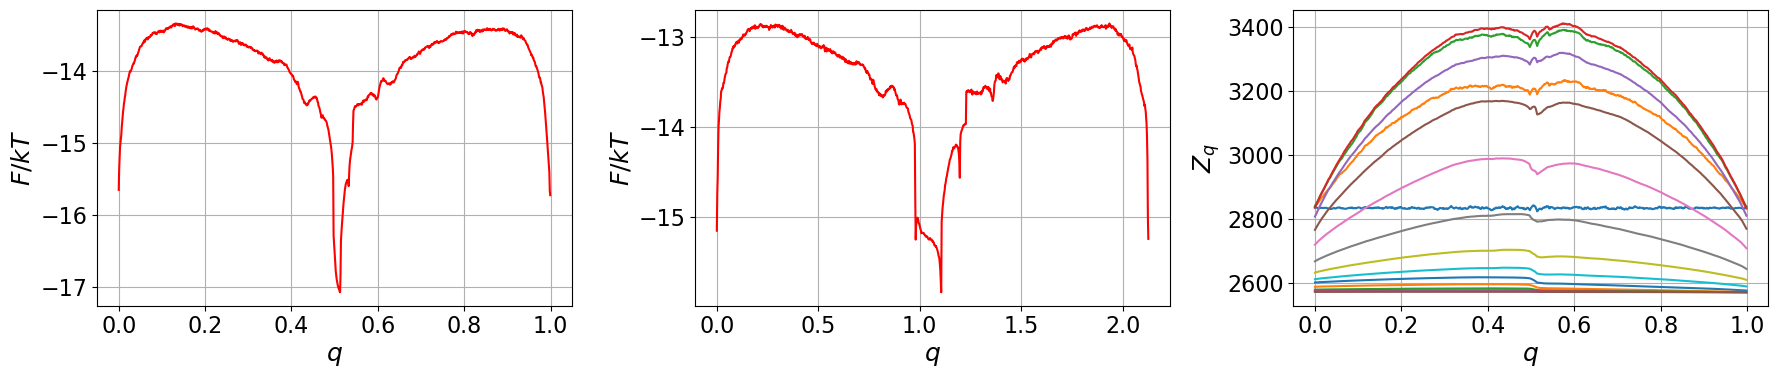

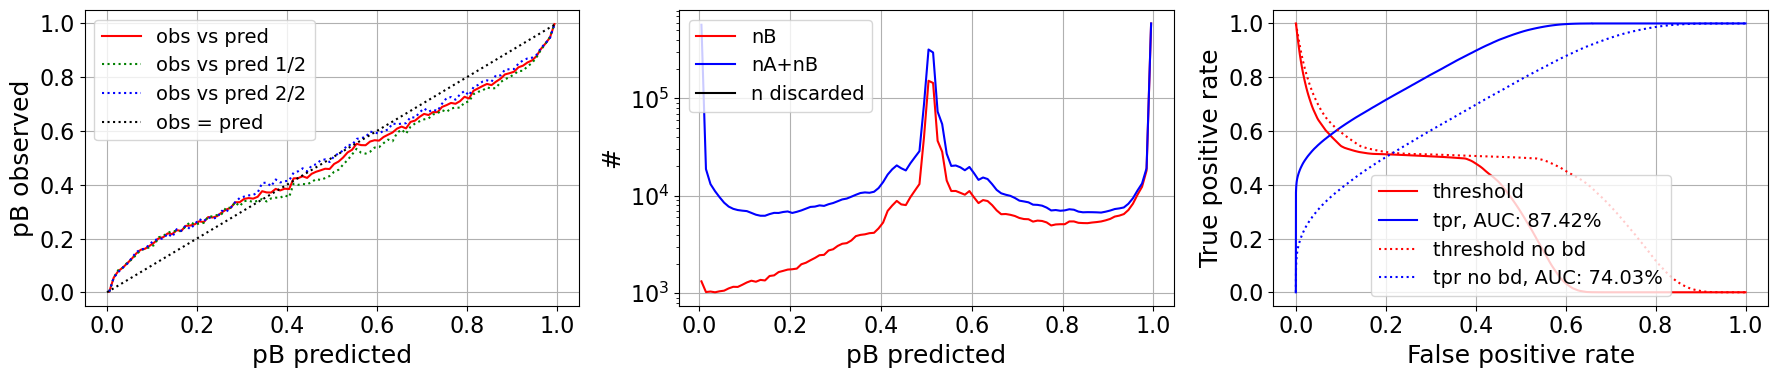

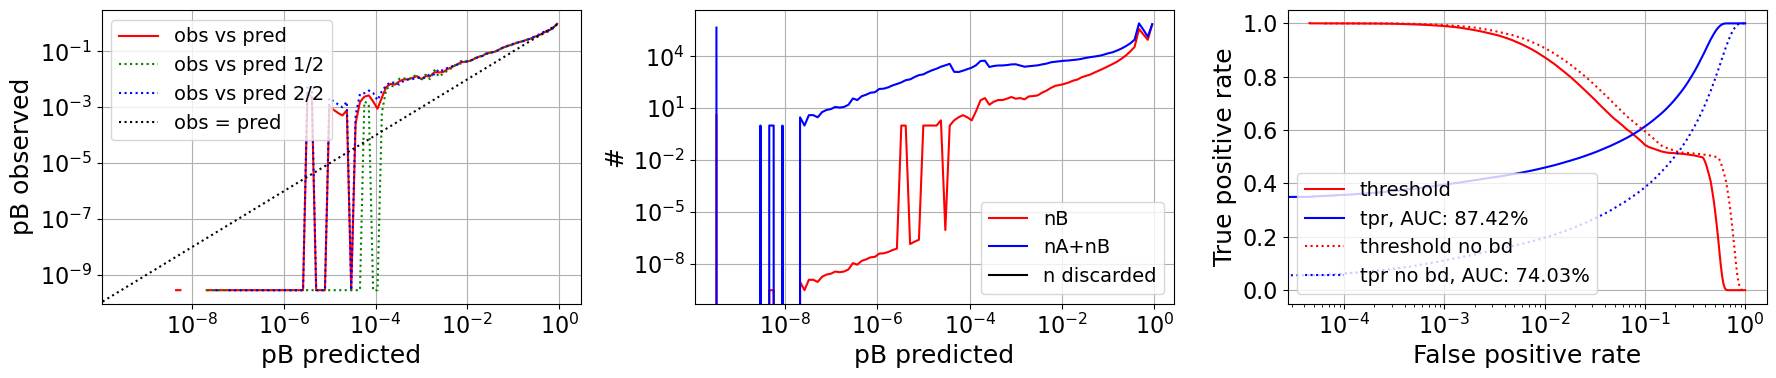

ValueError: shape mismatch: objects cannot be broadcast to a single shape.  Mismatch is between arg 0 with shape (3000000,) and arg 1 with shape (2999999,).

In [5]:
# Parameters
m = 1.0  # mass
gamma = 1.0  # friction coefficient
k_B = 1.0  # Boltzmann constant
T = 1.0  # temperature
dt = 0.005  # time step
num_steps = 3000000  # number of steps
x0 = -0.17# initial position
v0 = 0.0  # initial velocity

wall_dx  = 0.1
k = 100
bleft  = -0.25
bright = 0.25
deltaf = 1.2
height = 0.15
width = 0.1
dB = 0

# Potential function U(x)
def potential(x):
    #return -math.exp(-(x-0.5)**2/0.04)*1.5
    L = bright - bleft     # width of 1 bump
    xleft = bleft - wall_dx - width
    xright = bright + wall_dx + width

    if x < xleft:
        v_pot = k*(x-xleft)**2/2.
    elif x > xright:
        v_pot = k*(x-xright)**2/2.
    elif x < bleft-width:
        v_pot = np.zeros_like(x)
    elif x > bright+width:
        v_pot = np.zeros_like(x) + dB*height
    elif x < bleft:
        v_pot = height/2 * (1 - np.cos(np.pi*(x-bleft+width)/width))
    elif x > bright:
        v_pot = (1-dB)*height/2 * (1 - np.cos(np.pi*(x-bright-width)/width)) + dB*height
    else:
        v_pot = height + deltaf/2 * (-1 + np.cos(2*np.pi*(x-bleft)/L))

    return v_pot.sum()

# Gradient of the potential (force)
def force(x):
    #return -(x-0.5)*2/0.04*math.exp(-(x-0.5)**2/0.04)*1.5
    
    L = bright - bleft     # width of 1 bump
    xleft = bleft - wall_dx - width
    xright = bright + wall_dx + width

    if x < xleft:
        force = -k*(x-xleft)
    elif x > xright:
        force = -k*(x-xright)
    elif (x < bleft-width) or (x > bright+width):
            force = 0
    elif x < bleft:
        force = -height*np.pi / (2*width) * np.sin(np.pi*(x-bleft+width)/width)
    elif x > bright:
        force = -(1-dB)*height*np.pi / (2*width) * np.sin(np.pi*(x-bright-width)/width)
    else:
        force =  np.pi * deltaf/L * np.sin(2*np.pi*(x-bleft)/L) 

    # forces = np.ones(1) * force
    # virial = np.zeros((1,1))

    return force

# Initialize arrays to store positions and velocities
positions = np.zeros(num_steps)
velocities = np.zeros(num_steps)

# Initial conditions
positions[0] = x0
velocities[0] = v0

# GJF coefficients
a = (1 - gamma*dt/(2*m)) / (1 + gamma*dt/(2*m))
b = 1 / (1 + gamma*dt/(2*m))
# Random impulse standard deviation
sigma = np.sqrt(2*gamma*k_B*T*dt)
# Initial random 
rng = np.random.default_rng(0)
beta = sigma * rng.standard_normal(num_steps)

# First step: use the standard GJF update with the initial velocity v0
F0 = force(x0)
positions[1] = x0 + b*dt*v0 + b*dt**2/(2*m)*F0 + b*dt/(2*m)*beta[1]

np.random.seed(0)
# Simulation loop
for i in range(1, num_steps-1):
    #x = positions[i-1]
    #v = velocities[i-1]
    
    # Calculate forces
   # F = force(x)
    
    # Generate random noise
    #xi = np.random.normal(0, 1)
    
    # Update velocity and position using the Euler-Maruyama method
    #v = v + (-gamma * v + F / m) * dt + np.sqrt(2 * gamma * k_B * T / m) * xi * np.sqrt(dt)
    #x = x + v * dt

    #bjf
    #bi = beta[i]

   # x_new = x + b*dt*v + b*dt**2/(2*m)*F + b*dt/(2*m)*bi
    #F_new = force(x_new)
   # v = a*v + dt/(2*m)*(a*F + F_new) + b/m*bi

    #x, F = x_new, F_new
    
    # Apply boundary conditions (reflective walls)
    #if x < 0:
     #   x = 0
      #  v = -v  # Reflect velocity
    #elif x > 1:
    #    x = 1
    #    v = -v  # Reflect velocity
    
    # Store positions and velocities
    #positions[i] = x
    positions[i+1] = (2*b*positions[i] - a*positions[i-1]
                      + b*dt**2/m * force(positions[i])
                      + b*dt/(2*m) * (beta[i+1] + beta[i]))
    #velocities[i] = v
    
velocities[1:] = np.diff(positions) / dt
# Plot the results
time = np.linspace(0, num_steps * dt, num_steps)
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(time[:1000], positions[:1000])
plt.xlabel('Time')
plt.ylabel('Position')
plt.title('Position vs Time')

plt.subplot(1, 2, 2)
plt.hist(positions, bins=50, density=True)
plt.xlabel('Position')
plt.ylabel('Probability density')
plt.title('Position Distribution')

plt.tight_layout()
plt.show()


i_traj=np.ones_like(positions)
t_traj=np.asarray(range(len(positions)))
from scipy.interpolate import griddata

def qxv(q,x,v):

    xi = np.linspace(-0.35, 0.35, 100)
    vi = np.linspace(-3, 3, 100)
    xi, vi = np.meshgrid(xi, vi)

    qi = griddata((x, v), q, (xi, vi), method='cubic')
    qi = np.clip(qi, 0, 1)
    levels = [0, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.98, 0.99, 1]

    
    # Create the contour plot with specified contour lines
    contour = plt.contourf(xi, vi, qi, levels=levels, cmap="RdBu_r")
    contour_lines = plt.contour(xi, vi, qi, levels=levels, colors='grey', alpha=0.5)

    plt.colorbar(contour, label='q value')
    plt.xlabel('x')
    plt.ylabel('v')
    plt.title('Contour plot of q(x, v)')
    plt.grid()
    plt.show()
    
    
def comp_y(): return positions

history=[0,1]
yr_type=['y(t-d),y(t)']

q=optimalrcs.CommittorNE(boundary0=positions<-0.35,boundary1=positions>0.35, i_traj=i_traj, t_traj=t_traj)
np.random.seed(0)
optimalrcs.envelope_scale=1000000
q.fit_transform(comp_y,history_delta_t=history,gamma=0,max_iter=2000,history_type=yr_type, history_shift_type='r(t)',delta_r2_max_change_allowed=10000)
optimalrcs.envelope_scale=0.01
q.fit_transform(comp_y,history_delta_t=history,gamma=0,max_iter=10000,history_type=yr_type, history_shift_type='r(t)')

q.plots_feps(delta_t_sim=0.01)
q.plots_obs_pred()
q.plots_obs_pred(log_scale=True)
plt.show()
qxv(q.r_traj.get(),positions,velocities)

3000000 3000000


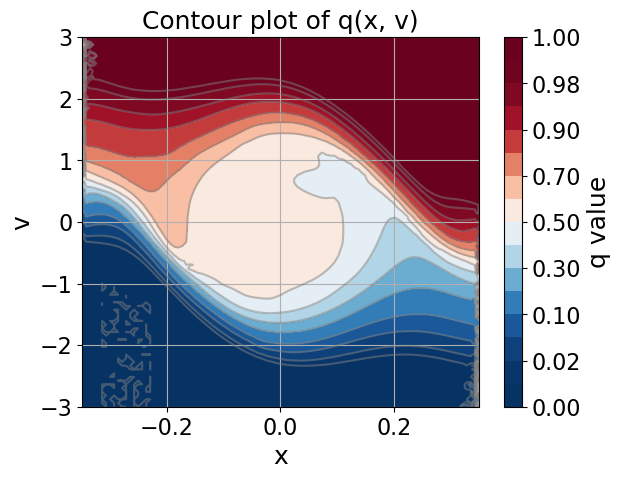

In [14]:
velocities = np.zeros_like(positions)
velocities[0] = v0
velocities[1:]= np.diff(positions) / dt
qxv(q.r_traj.get(),positions,velocities)

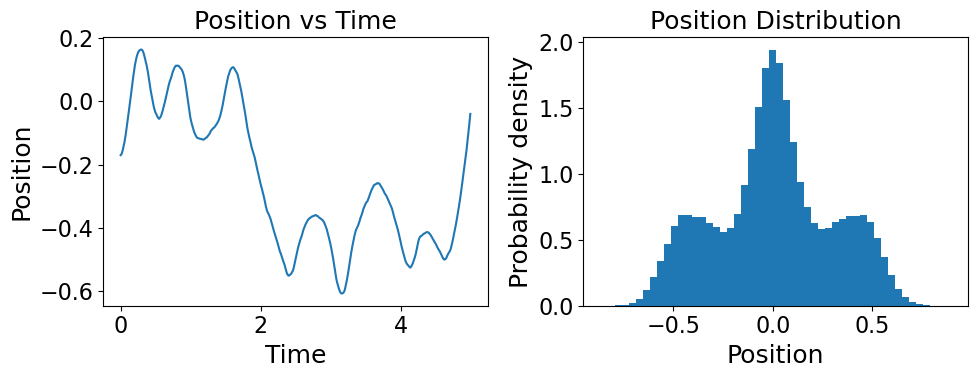

In [ ]:
# Parameters
m = 1.0  # mass
gamma = 1.0  # friction coefficient
k_B = 1.0  # Boltzmann constant
T = 1.0  # temperature
dt = 0.005  # time step
num_steps = 3000000  # number of steps
x0 = -0.17# initial position
v0 = 0.0  # initial velocity

wall_dx  = 0.1
k = 100
bleft  = -0.25
bright = 0.25
deltaf = 1.2
height = 0.15
width = 0.1
dB = 0

# Potential function U(x)
def potential(x):
    #return -math.exp(-(x-0.5)**2/0.04)*1.5
    L = bright - bleft     # width of 1 bump
    xleft = bleft - wall_dx - width
    xright = bright + wall_dx + width

    if x < xleft:
        v_pot = k*(x-xleft)**2/2.
    elif x > xright:
        v_pot = k*(x-xright)**2/2.
    elif x < bleft-width:
        v_pot = np.zeros_like(x)
    elif x > bright+width:
        v_pot = np.zeros_like(x) + dB*height
    elif x < bleft:
        v_pot = height/2 * (1 - np.cos(np.pi*(x-bleft+width)/width))
    elif x > bright:
        v_pot = (1-dB)*height/2 * (1 - np.cos(np.pi*(x-bright-width)/width)) + dB*height
    else:
        v_pot = height + deltaf/2 * (-1 + np.cos(2*np.pi*(x-bleft)/L))

    return v_pot.sum()

# Gradient of the potential (force)
def force(x):
    #return -(x-0.5)*2/0.04*math.exp(-(x-0.5)**2/0.04)*1.5
    
    L = bright - bleft     # width of 1 bump
    xleft = bleft - wall_dx - width
    xright = bright + wall_dx + width

    if x < xleft:
        force = -k*(x-xleft)
    elif x > xright:
        force = -k*(x-xright)
    elif (x < bleft-width) or (x > bright+width):
            force = 0
    elif x < bleft:
        force = -height*np.pi / (2*width) * np.sin(np.pi*(x-bleft+width)/width)
    elif x > bright:
        force = -(1-dB)*height*np.pi / (2*width) * np.sin(np.pi*(x-bright-width)/width)
    else:
        force =  np.pi * deltaf/L * np.sin(2*np.pi*(x-bleft)/L) 

    # forces = np.ones(1) * force
    # virial = np.zeros((1,1))

    return force

# Initialize arrays to store positions and velocities
positions = np.zeros(num_steps)
velocities = np.zeros(num_steps)

# Initial conditions
positions[0] = x0
velocities[0] = v0


np.random.seed(0)
# Simulation loop
for i in range(1, num_steps):
    x = positions[i-1]
    v = velocities[i-1]
    
    # Calculate forces
    F = force(x)
    
    # Generate random noise
    xi = np.random.normal(0, 1)
    
    # Update velocity and position using the Euler-Maruyama method
    v = v + (-gamma * v + F / m) * dt + np.sqrt(2 * gamma * k_B * T / m) * xi * np.sqrt(dt)
    x = x + v * dt
    
    # Apply boundary conditions (reflective walls)
    #if x < 0:
     #   x = 0
      #  v = -v  # Reflect velocity
    #elif x > 1:
    #    x = 1
    #    v = -v  # Reflect velocity
    
    # Store positions and velocities
    positions[i] = x
    velocities[i] = v

# Plot the results
time = np.linspace(0, num_steps * dt, num_steps)
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(time[:1000], positions[:1000])
plt.xlabel('Time')
plt.ylabel('Position')
plt.title('Position vs Time')

plt.subplot(1, 2, 2)
plt.hist(positions, bins=50, density=True)
plt.xlabel('Position')
plt.ylabel('Probability density')
plt.title('Position Distribution')

plt.tight_layout()
plt.show()


i_traj=np.ones_like(positions)
t_traj=np.asarray(range(len(positions)))
from scipy.interpolate import griddata

def qxv(q,x,v):

    xi = np.linspace(-0.35, 0.35, 100)
    vi = np.linspace(-3, 3, 100)
    xi, vi = np.meshgrid(xi, vi)

    qi = griddata((x, v), q, (xi, vi), method='cubic')
    qi = np.clip(qi, 0, 1)
    levels = [0, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.98, 0.99, 1]

    
    # Create the contour plot with specified contour lines
    contour = plt.contourf(xi, vi, qi, levels=levels, cmap="RdBu_r")
    contour_lines = plt.contour(xi, vi, qi, levels=levels, colors='grey', alpha=0.5)

    plt.colorbar(contour, label='q value')
    plt.xlabel('x')
    plt.ylabel('v')
    plt.title('Contour plot of q(x, v)')
    plt.grid()
    plt.show()
    
    
def comp_y(): return positions

history=[0,1]
yr_type=['y(t-d),y(t)']

q=optimalrcs.CommittorNE(boundary0=positions<-0.35,boundary1=positions>0.35, i_traj=i_traj, t_traj=t_traj)
np.random.seed(0)
optimalrcs.envelope_scale=1000000
q.fit_transform(comp_y,history_delta_t=history,gamma=0,max_iter=2000,history_type=yr_type, history_shift_type='r(t)',delta_r2_max_change_allowed=10000)
optimalrcs.envelope_scale=0.01
q.fit_transform(comp_y,history_delta_t=history,gamma=0,max_iter=10000,history_type=yr_type, history_shift_type='r(t)')

q.plots_feps(delta_t_sim=0.01)
q.plots_obs_pred()
q.plots_obs_pred(log_scale=True)
plt.show()
qxv(q.r_traj.get(),positions,velocities)

In [6]:
np.save('euler_md_wel_lgv_3M.npy', np.column_stack((positions, velocities)))

#=1000, xent=0.399363, mse=0.139923, sdzq=50.166, dzq=259.636, dr2=4543.15, auc=0.870418, |dx|=0.18425, time=50.6473
#=2000, xent=0.399239, mse=0.139914, sdzq=50.6729, dzq=261.306, dr2=4546.79, auc=0.870453, |dx|=0.000399248, time=101.901
#=3000, xent=0.3958, mse=0.138847, sdzq=19.9771, dzq=102.214, dr2=4933.84, auc=0.87245, |dx|=0.0344348, time=51.0372
#=4000, xent=0.396609, mse=0.139174, sdzq=51.8078, dzq=170.858, dr2=4881.38, auc=0.871923, |dx|=0.0240109, time=83.6782
#=5000, xent=0.396876, mse=0.139195, sdzq=31.4746, dzq=149.979, dr2=5098.37, auc=0.872112, |dx|=0.0360221, time=117.242
#=6000, xent=0.396662, mse=0.139124, sdzq=63.5468, dzq=148.783, dr2=4709.88, auc=0.871834, |dx|=0.0267763, time=168.96
#=7000, xent=0.398268, mse=0.139581, sdzq=55.2754, dzq=327.467, dr2=4756.2, auc=0.871288, |dx|=0.0245048, time=220.58
#=8000, xent=0.537632, mse=0.188627, sdzq=1460.86, dzq=3183.45, dr2=2695.21, auc=0.828454, |dx|=0.212561, time=272.377
#=9000, xent=0.398875, mse=0.139974, sdzq=55.293

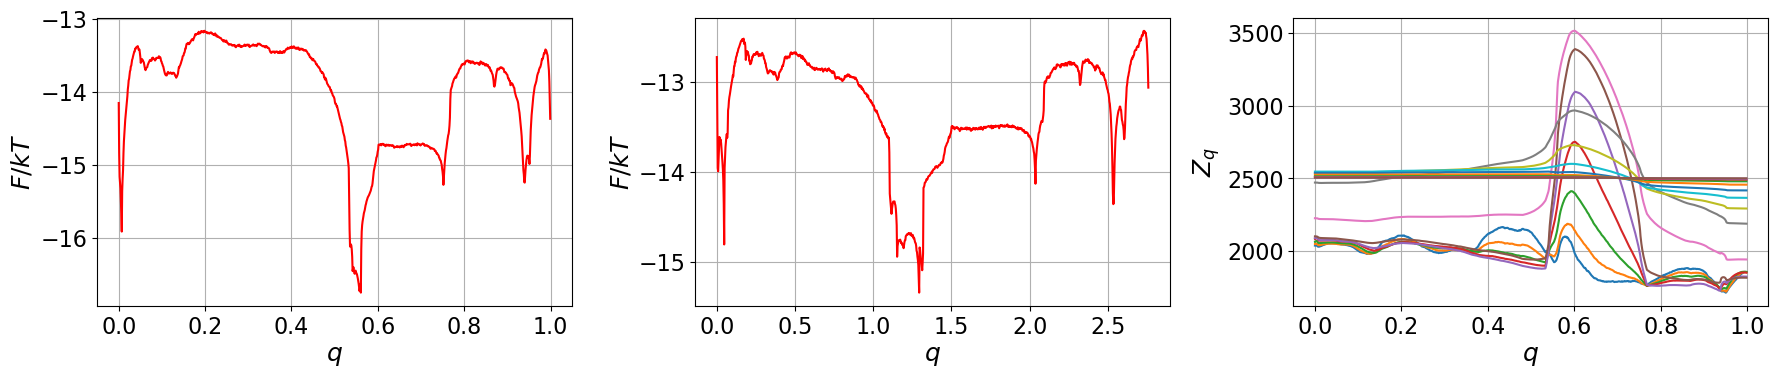

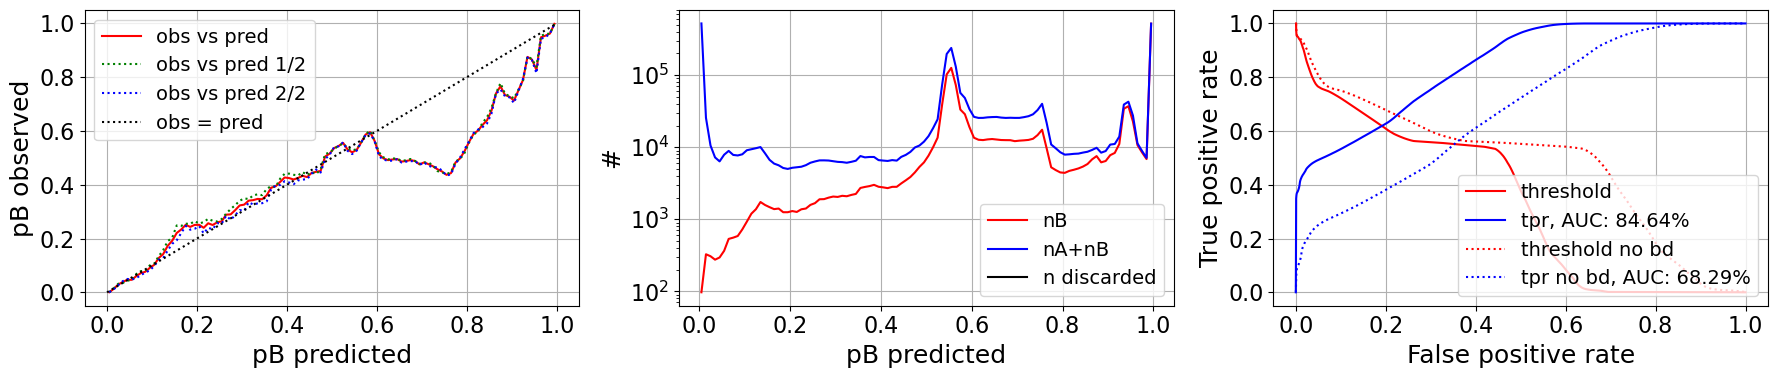

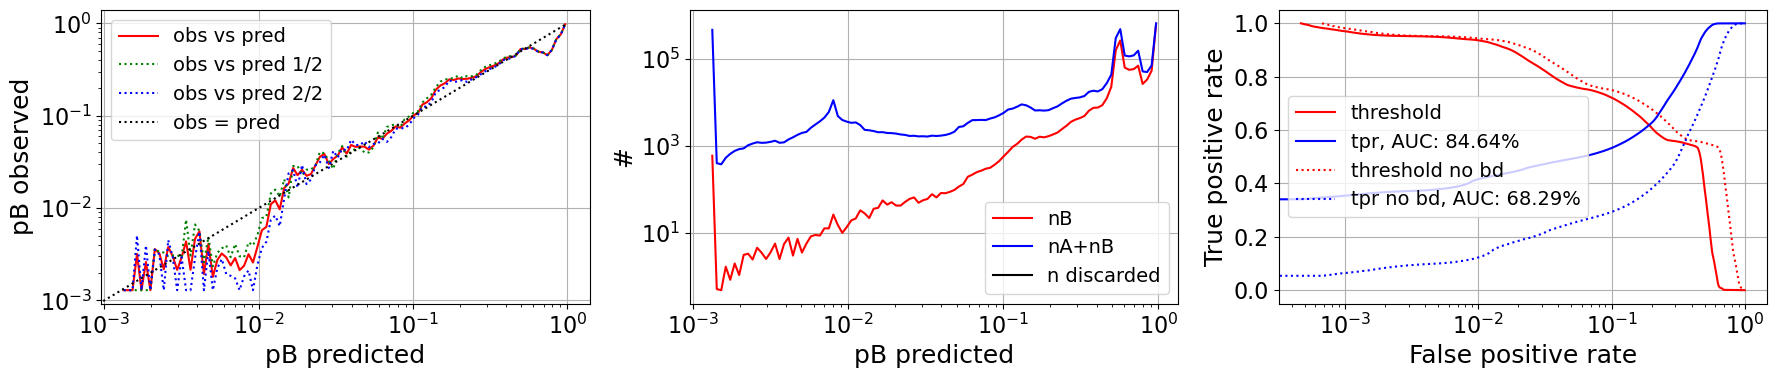

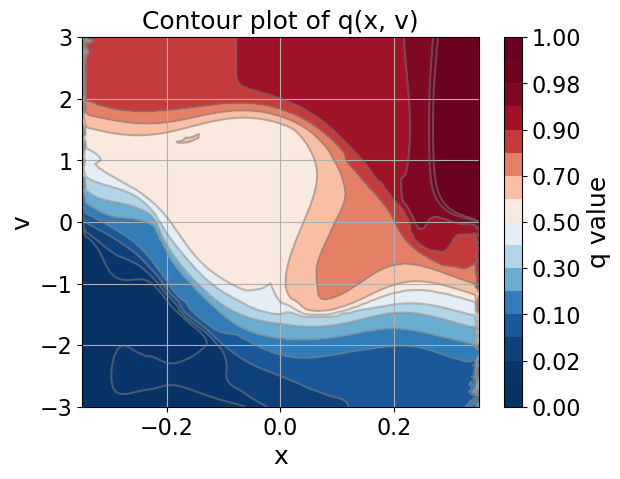

In [7]:
i_traj=np.ones_like(positions)
t_traj=np.asarray(range(len(positions)))
from scipy.interpolate import griddata
    
def comp_y(): c = np.random.choice([0,1]); return positions if c==0 else velocities

history=[0,1]
yr_type=['y(t-d),y(t)']

q=optimalrcs.CommittorNE(boundary0=positions<-0.35,boundary1=positions>0.35, i_traj=i_traj, t_traj=t_traj)
np.random.seed(1)
optimalrcs.envelope_scale=1000000
q.fit_transform(comp_y,gamma=0.1,max_iter=2000,delta_r2_max_change_allowed=10000)
optimalrcs.envelope_scale=0.01
q.fit_transform(comp_y,gamma=0.1,max_iter=10000)

q.plots_feps(delta_t_sim=0.01)
q.plots_obs_pred()
q.plots_obs_pred(log_scale=True)
plt.show()
qxv(q.r_traj.get(),positions,velocities)

#=1000, xent=0.395096, mse=0.138586, sdzq=173.368, dzq=837.727, dr2=10339, auc=0.872934, |dx|=0.191329, time=25.4585
#=2000, xent=0.395016, mse=0.138491, sdzq=142.924, dzq=713.021, dr2=10375.6, auc=0.873143, |dx|=0.00269176, time=50.9685
#=3000, xent=0.39355, mse=0.137915, sdzq=10.9937, dzq=58.1501, dr2=10306.2, auc=0.874833, |dx|=0.0200568, time=25.4145
#=4000, xent=0.393504, mse=0.137892, sdzq=8.94545, dzq=43.9171, dr2=10291.5, auc=0.874896, |dx|=0.00212578, time=50.7999
#=5000, xent=0.393501, mse=0.137894, sdzq=10.0525, dzq=34.2859, dr2=10284.7, auc=0.874913, |dx|=0.00121111, time=76.1868
#=6000, xent=0.393467, mse=0.137882, sdzq=9.21215, dzq=32.4285, dr2=10280.5, auc=0.874934, |dx|=0.000836964, time=101.549
#=7000, xent=0.393471, mse=0.137883, sdzq=9.38772, dzq=33.0778, dr2=10275.8, auc=0.874937, |dx|=0.00047416, time=126.923
#=8000, xent=0.393468, mse=0.13788, sdzq=9.33216, dzq=30.886, dr2=10276, auc=0.874946, |dx|=0.000359009, time=152.281
#=9000, xent=0.393458, mse=0.137878, sdz

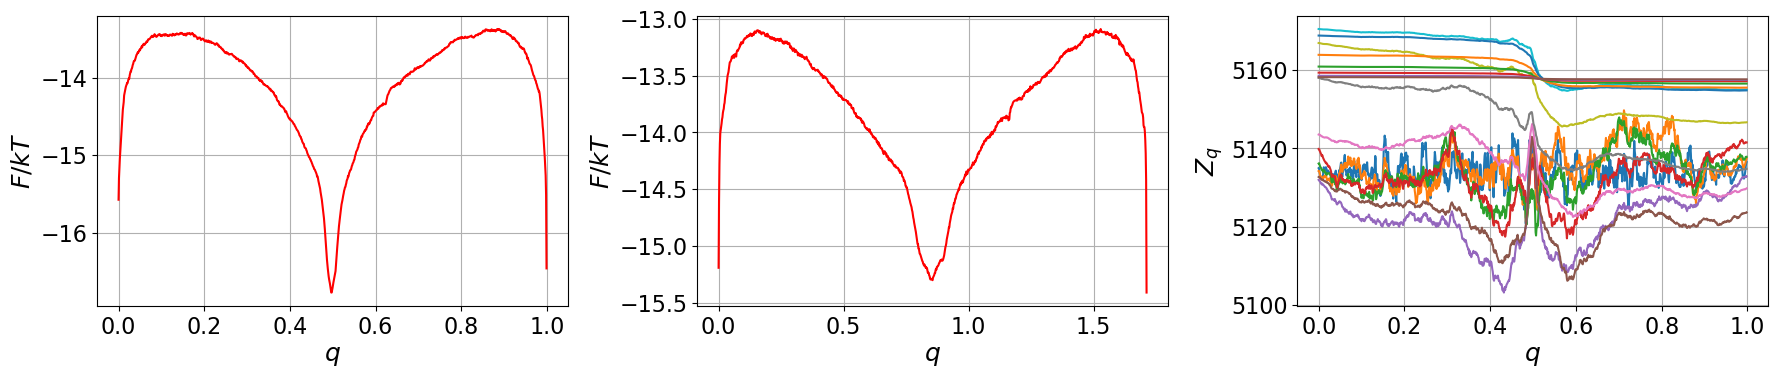

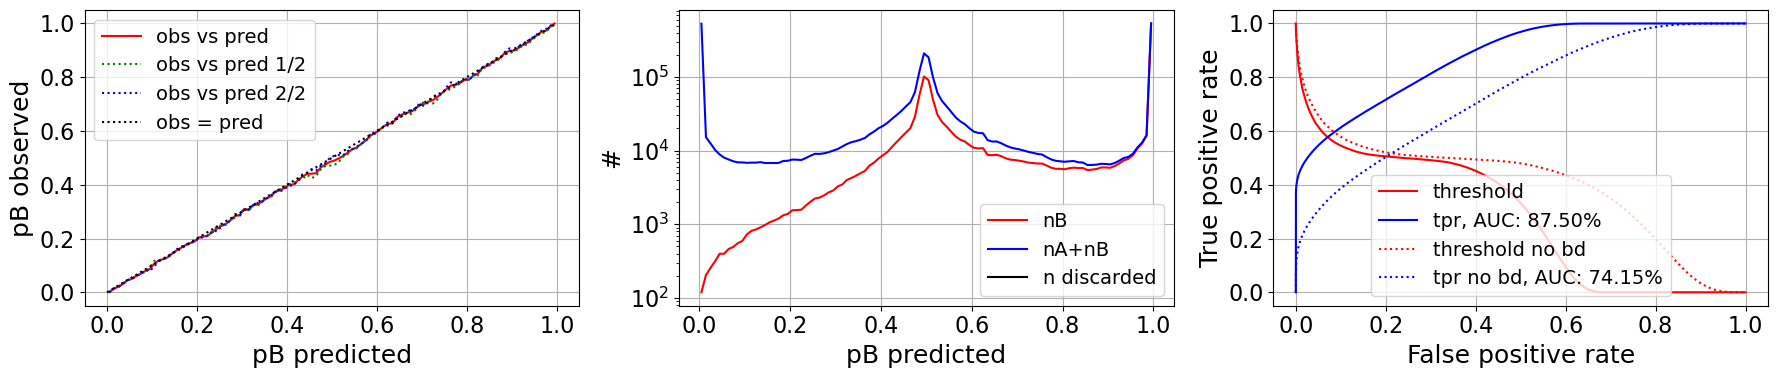

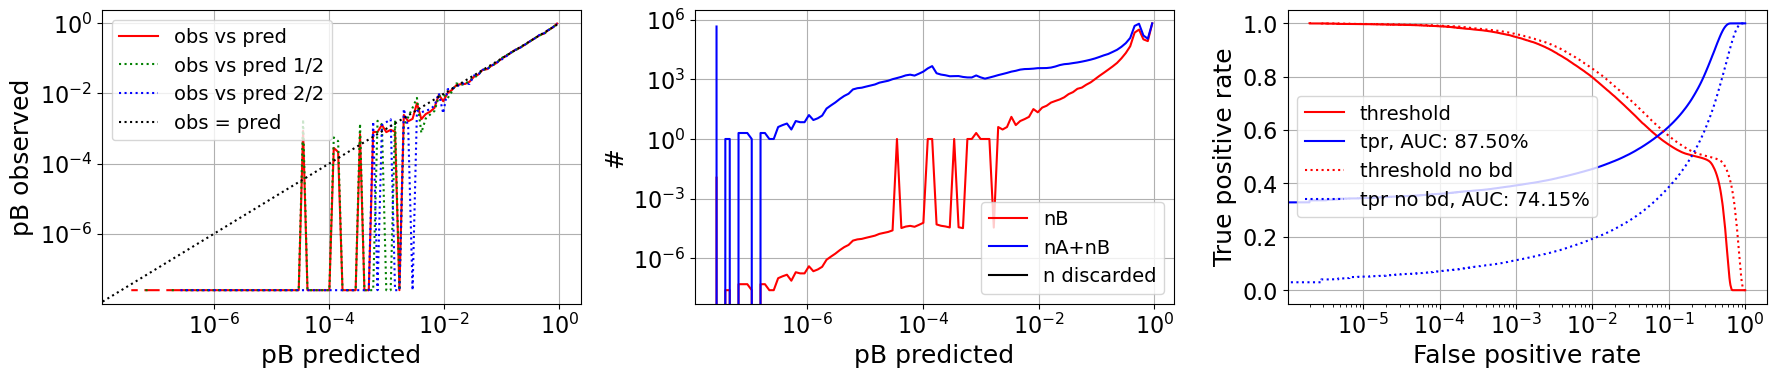

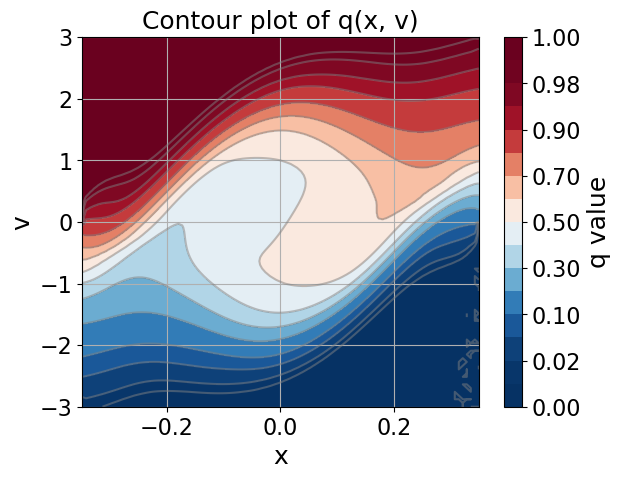

In [7]:
positions_r=positions[::-1].copy()


def comp_y(): return positions_r

history=[0,1]
yr_type=['y(t-d),y(t)']

q_r=optimalrcs.CommittorNE(boundary0=positions_r>0.35,boundary1=positions_r<-0.35, i_traj=i_traj, t_traj=t_traj)
np.random.seed(0)
optimalrcs.envelope_scale=1000000
q_r.fit_transform(comp_y,history_delta_t=history,gamma=0,max_iter=2000,history_type=yr_type, history_shift_type='r(t)',delta_r2_max_change_allowed=10000)
optimalrcs.envelope_scale=0.01
q_r.fit_transform(comp_y,history_delta_t=history,gamma=0,max_iter=10000,history_type=yr_type, history_shift_type='r(t)')

q_r.plots_feps(delta_t_sim=0.01)
q_r.plots_obs_pred()
q_r.plots_obs_pred(log_scale=True)
plt.show()
qxv(q_r.r_traj.get()[::-1],np.roll(positions,-1),np.roll(velocities,-1))

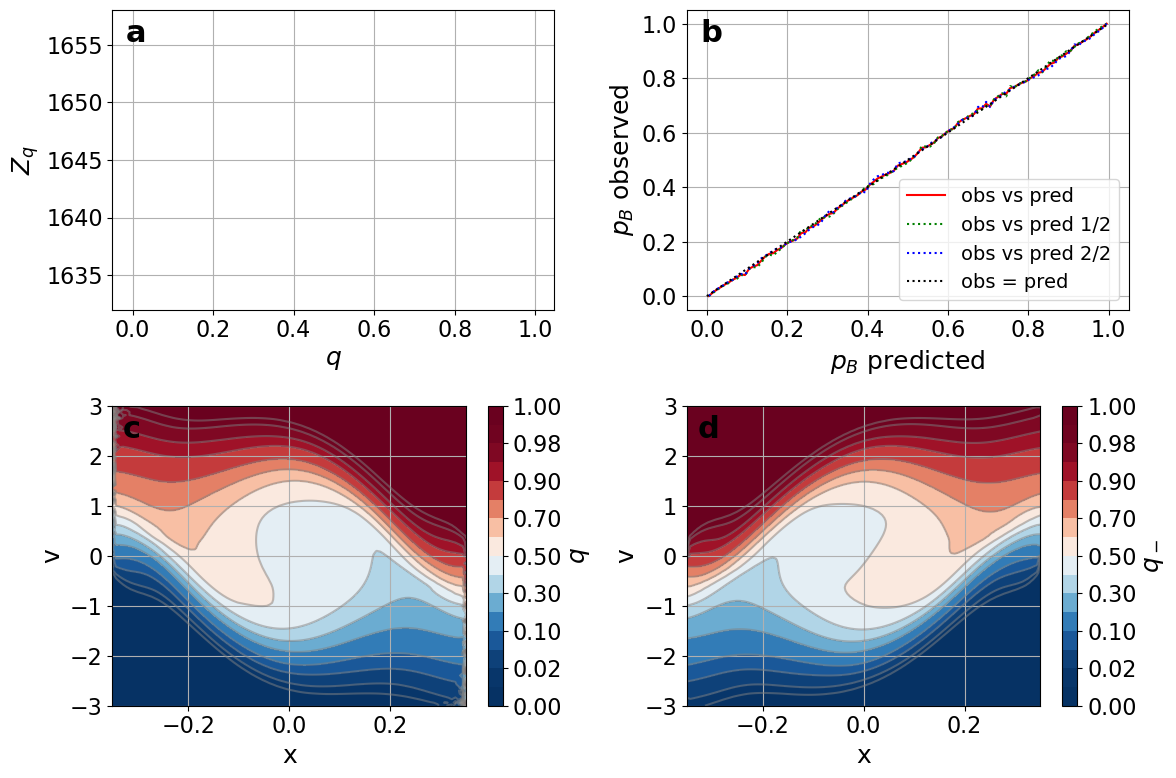

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
letters = ['a', 'b', 'c', 'd', 'e', 'f']
for i, ax in enumerate(axes.flat):
    ax.text(0.03, 0.97, letters[i], transform=ax.transAxes, fontsize=22, fontweight='bold', va='top')

def qxv(q,x,v,ax,label='q'):

    xi = np.linspace(-0.35, 0.35, 100)
    vi = np.linspace(-3, 3, 100)
    xi, vi = np.meshgrid(xi, vi)

    qi = griddata((x, v), q, (xi, vi), method='cubic')
    qi = np.clip(qi, 0.0001, 1-0.0001)
    levels = [0, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.98, 0.99, 1]

    
    # Create the contour plot with specified contour lines
    contour = ax.contourf(xi, vi, qi, levels=levels, cmap="RdBu_r")
    contour_lines = ax.contour(xi, vi, qi, levels=levels, colors='grey', alpha=0.5)
    fig.colorbar(contour, ax=ax, label=label)
    ax.set(xlabel='x',ylabel='v')
    ax.grid()

qxv(q.r_traj.get(),positions,velocities,axes[1,0],label='$q$')
qxv(q_r.r_traj.get()[::-1],np.roll(positions,-1),np.roll(velocities,-1),axes[1,1],label='$q_-$')

plots.plot_zq(axes[0,0], q.r_traj, q.b_traj, q.i_traj, q.future_boundary, q.past_boundary)
axes[0,0].set(ylim=(1635-3,1655+3))
plots.plot_obs_pred_q(axes[0,1], q.r_traj, q.future_boundary)
axes[0,1].legend(loc='lower right')
axes[0,1].set(ylabel='$p_B$ observed', xlabel='$p_B$ predicted')
fig.tight_layout()